# SEADOTS: From Interoperable Marine Data to Decision Support
## 1-Hour Hands-on Workshop

### Learning objectives
- Load data from multiple sources
- Understand semantic interoperability
- Create common indicators
- Compare scenarios
- Support a policy decision

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## Step 1: Load data

In [2]:
fish=pd.read_csv('fish_stock.csv')
wind=pd.read_csv('wind_capacity.csv')
env=pd.read_csv('environmental_status.csv')
fish.head()

,year,biomass,catch_ktons
0,2015,82,28
1,2016,80,29
2,2017,78,30
3,2018,77,31
4,2019,75,32


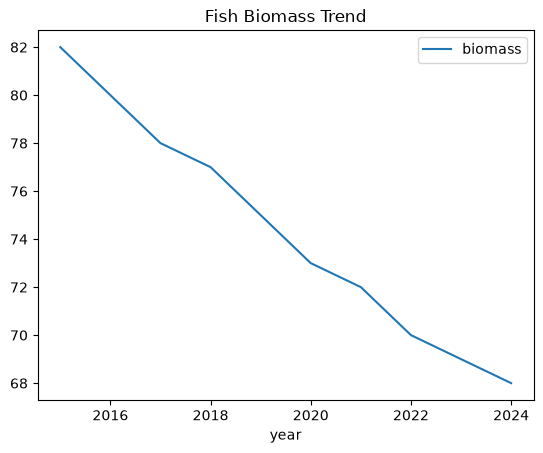

In [3]:
fish.plot(x='year',y='biomass',title='Fish Biomass Trend')
plt.show()

## Step 2: Interoperability Exercise

In [4]:
terms={'fish_biomass':'fish_stock_indicator','spawning_biomass':'fish_stock_indicator','abundance_index':'fish_stock_indicator'}
pd.DataFrame(list(terms.items()),columns=['Source term','Harmonized term'])

,Source term,Harmonized term
0,fish_biomass,fish_stock_indicator
1,spawning_biomass,fish_stock_indicator
2,abundance_index,fish_stock_indicator


Interoperability is agreeing on meaning, not only data exchange.

## Step 3: Build Indicators

In [5]:
latest={
'fish':fish.iloc[-1]['biomass'],
'wind':wind.iloc[-1]['capacity_gw'],
'env':env.iloc[-1]['environmental_status']}
latest

{'fish': np.int64(68), 'wind': np.float64(4.0), 'env': np.int64(67)}

## Step 4: Scenario Analysis

In [6]:
def score(fish,wind,env):
    return fish*0.5 + env*0.3 + wind*5*0.2

scenarios=pd.DataFrame([
['Current',68,4.0,67],
['Wind +30%',65,5.2,65],
['Wind +30% + Mitigation',70,5.2,69]
],columns=['scenario','fish','wind','env'])

scenarios['score']=scenarios.apply(lambda r: score(r['fish'],r['wind'],r['env']),axis=1)
scenarios

,scenario,fish,wind,env,score
0,Current,68,4.0,67,58.1
1,Wind +30%,65,5.2,65,57.2
2,Wind +30% + Mitigation,70,5.2,69,60.9


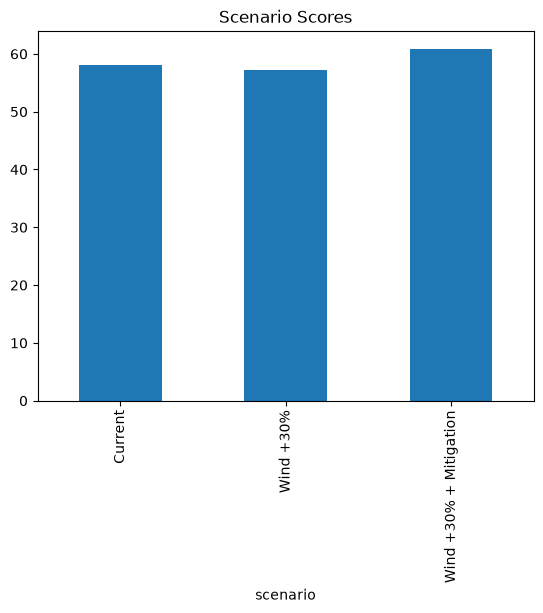

In [7]:
scenarios.plot.bar(x='scenario',y='score',legend=False,title='Scenario Scores')
plt.show()

## Step 5: Multi-Criteria Decision Making

In [ ]:
weights={'ecosystem':0.4,'fisheries':0.3,'energy':0.3}

mcda=scenarios.copy()
mcda['mcda_score']=mcda['env']*0.4 + mcda['fish']*0.3 + (mcda['wind']*20)*0.3
mcda.sort_values('mcda_score',ascending=False)

## Discussion
1. Which scenario would you recommend?
2. What additional data would improve confidence?
3. Which interoperability issues could affect the decision?